# Exercise 4
Nico Reiterer - 5191 2112

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import circulant

import time

## 4.2 Periodic functions - Solving with FFT

In [ ]:
def fft(y: np.array):
    """ 
        FFT algorithm based on "Algorithm 3" from the lecture notes. However, it is only working for len(y) == power of 2 
        y: data
    """    
    n = len(y)
    if n == 1:
        return y[0]
    
    m = n // 2
    omega = np.exp(-2 * np.pi * 1j/n)

    j = np.arange(m)

    g = y[:m] + y[m:]                       # line 8: g_j = y_j + y_{j+m}
    h = (y[:m] - y[m:]) * omega**j          # line 9: h_j = (y_j - y_{j+m}) omega^j
    
    yhat = np.empty(n, dtype=complex)
    yhat[0::2] = fft(g)                     # line 10: even coefficients
    yhat[1::2] = fft(h)                     # line 11: odd coefficients
    return yhat



In [26]:
# defining useful functions here
f = lambda x: 1 / (2 - np.cos(x))
g = lambda x: np.abs(np.sin(x / 2))
yhat = lambda y: np.fft.fft(y) / len(y) # using numpy since $n$ is odd.

k_calc = lambda m: np.concatenate((np.arange(0, m + 1), np.arange(-m, 0))) # [0, 1, ..., m, -m, ..., -1]
q_n = lambda x, d, k: np.exp(1j * np.outer(x, k)) @ d

def routine42(n, x_j, y, x_fine=np.linspace(0, 2*np.pi, 10001), verbose=True):
    m = (n - 1) // 2
    d = yhat(y)
    k = k_calc(m)

    q_knots = q_n(x_j, d, k)
    q_fine  = q_n(x_fine, d, k)

    if verbose:
        print("max |q_n(x_j) - y_j| :", np.max(np.abs(q_knots - y)))
        print("max |Im q_n(x)|      :", np.max(np.abs(q_fine.imag)))

    return q_fine.real

In [27]:
n = 21
x_j = 2 * np.pi * np.arange(n)/n
y = f(x_j)

q = routine42(n, x_j=x_j, y=y)


max |q_n(x_j) - y_j| : 5.551991194044518e-16
max |Im q_n(x)|      : 8.772574261441088e-17


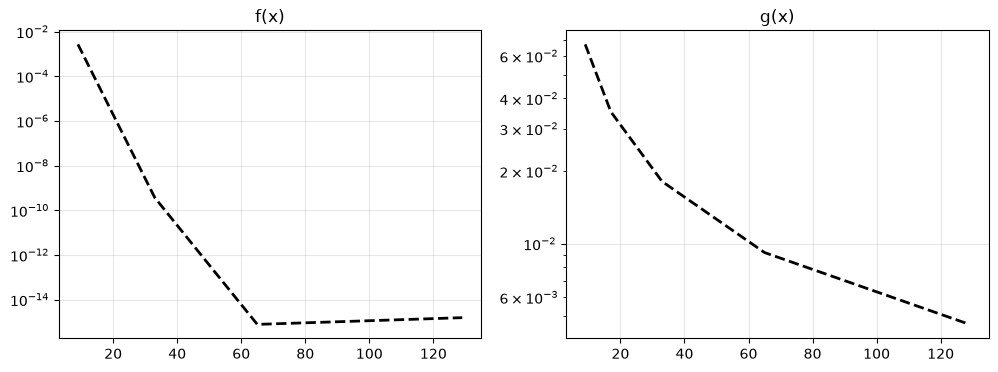

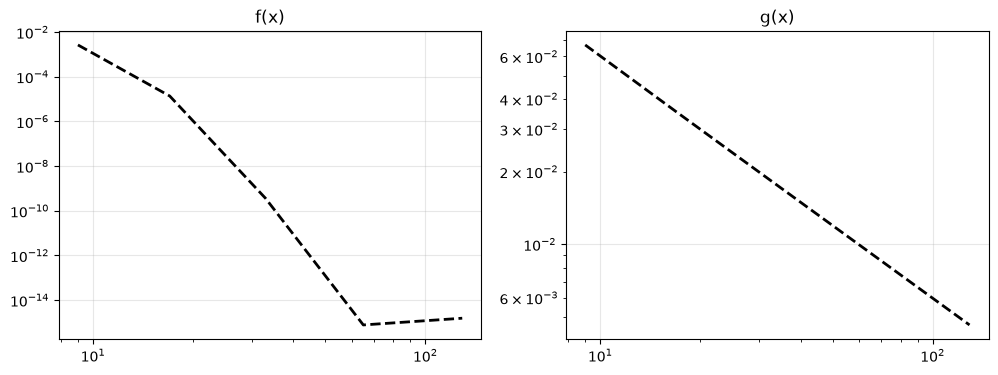

In [30]:
n_list = [9,17,33,65,129]
error_g = np.zeros(5)
error_f = np.zeros(5)

x_fine = np.linspace(0, 2*np.pi, 10001)
for i, n in enumerate(n_list):
    x_j = 2 * np.pi * np.arange(n) / n
    error_f[i] = np.max(np.abs(routine42(n, x_j, f(x_j), x_fine, verbose=False) - f(x_fine)))
    error_g[i] = np.max(np.abs(routine42(n, x_j, g(x_j), x_fine, verbose=False) - g(x_fine)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, error, name in zip(axes, [error_f, error_g], ["f(x)", "g(x)"]):
    ax.semilogy(n_list, error, "k--", lw=2)
    ax.set_title(f"{name}") 
    #ax.legend() 
    ax.grid(alpha=0.3)

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, error, name in zip(axes, [error_f, error_g], ["f(x)", "g(x)"]):
    ax.loglog(n_list, error, "k--", lw=2)
    ax.set_title(f"{name}") 
    #ax.legend() 
    ax.grid(alpha=0.3)

plt.show()

f (left panels):

+ Semilogy: a straight line down to $n \approx 65$. Every 10 extra n divide the error by about 1000.  That’s exponential convergence: a fixed amount of extra steps gets us you a fixed number of correct digits.
+ Loglog: The flat part after 65 is probably related to some  machine-precision floor, not interpolation errors.

g (right panels):
+ Semilogy: the curve flattens. Adding 10 points helps less and less, because 10 extra points is a big relative increase at $n = 10$ but a small one at $n = 120$.
+ Loglog: an almost perfect straight line, with slope $-1$. Doubling the number of points halves the error, every time. #Algebraic convergence: $C\, n^{-\alpha}$


## 4.3 Circulant Matrix

In [50]:
def routine43(N, b):
    c = np.zeros(N)
    c[0] = 2 * N**2 + 1
    c[1] = c[-1] = -N**2

    c_hat = np.fft.fft(c)
    b_hat = np.fft.fft(b)
    x = np.fft.ifft(b_hat / c_hat)
    return x.real

N =        4 | time = 4.43e-04 s 
N =        8 | time = 8.00e-05 s 
N =       16 | time = 2.84e-04 s 
N =       32 | time = 8.93e-05 s 
N =       64 | time = 1.44e-04 s 
N =      128 | time = 8.66e-05 s 
N =      256 | time = 2.30e-03 s 
N =      512 | time = 3.14e-03 s 
N =     1024 | time = 3.63e-04 s 
N =     2048 | time = 4.76e-04 s 
N =     4096 | time = 3.22e-04 s 
N =     8192 | time = 7.80e-04 s 
N =    16384 | time = 1.30e-03 s 
N =    32768 | time = 2.80e-03 s 
N =    65536 | time = 2.40e-02 s 
N =   131072 | time = 2.10e-02 s 
N =   262144 | time = 5.10e-02 s 
N =   524288 | time = 7.32e-02 s 
N =  1048576 | time = 2.28e-01 s 


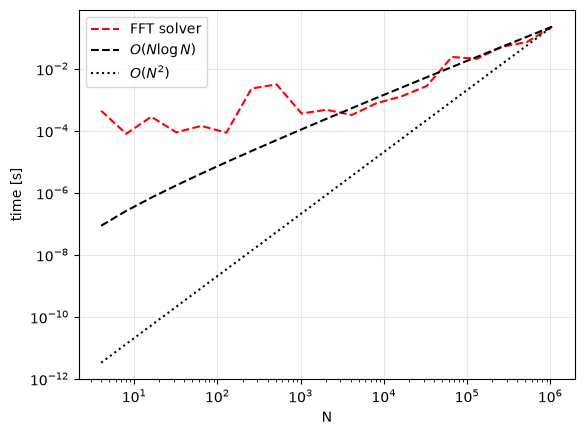

In [ ]:
Ns = 2 ** np.arange(2, 21)
timer = np.zeros(len(Ns))


for i, N in enumerate(Ns):
    b = np.ones(N)
    times = []
    start = time.perf_counter()
    x = routine43(N, b)
    times.append(time.perf_counter() - start)
    timer[i] = min(times)
    print(f"N = {N:8d} | time = {timer[i]:.2e} s ")

# nice, looks similar to figure 1.8 in the script
plt.loglog(Ns, timer, "r--", label="FFT solver")
plt.loglog(Ns, timer[-1] * (Ns*np.log2(Ns)) / (Ns[-1]*np.log2(Ns[-1])), "k--", label=r"$O(N\log N)$")
plt.loglog(Ns, timer[-1] * (Ns/Ns[-1])**2, "k:", label=r"$O(N^2)$")
plt.xlabel("N"); plt.ylabel("time [s]"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [74]:
np.convolve([1, 2, -1], [2, -1, 0, 1])

array([ 2,  3, -4,  2,  2, -1])

## 4.4b)

In [75]:
def ifft(y):
    """Inverse FFT via (1.40): F_n^{-1} y = conj(F_n(conj(y))) / n."""
    y = np.asarray(y, dtype=complex)
    return np.conj(fft(np.conj(y))) / len(y)

# coefficient vectors (monomial basis, lowest degree first)
a = np.array([1, 2, -1])        # A(z) = 1 + 2z - z^2
b = np.array([2, -1, 0, 1])     # B(z) = 2 - z + z^3
n = 8

# 1) zero-padding to length n
a_pad = np.concatenate((a, np.zeros(n - len(a))))
b_pad = np.concatenate((b, np.zeros(n - len(b))))

# 2) two FFTs
a_hat = fft(a_pad)
b_hat = fft(b_pad)

# 3) componentwise product + one inverse FFT (convolution theorem)
c = ifft(a_hat * b_hat)

print("max |Im c|:", np.max(np.abs(c.imag)))      # rounding noise only
c = np.round(c.real, 12) + 0.0                    # +0.0 turns -0. into 0.
print("FFT:   ", c)
print("direct:", np.convolve(a, b))

max |Im c|: 4.0489125678221406e-16
FFT:    [ 2.  3. -4.  2.  2. -1.  0.  0.]
direct: [ 2  3 -4  2  2 -1]
